In [1]:
import sys
print("python:", sys.version.split()[0])
print("kernel:", sys.executable, "\n")

for name in ["coffea", "uproot", "awkward", "numpy", "matplotlib", "hist", "mplhep", "vector"]:
    try:
        mod = __import__(name)
        print(f"  [ok]      {name:<12s} {getattr(mod, '__version__', '?')}")
    except ImportError:
        print(f"  [MISSING] {name}")

python: 3.10.14
kernel: /depot/cms/conda_envs/bhanda25/Coffea-Santosh/bin/python 

  [ok]      coffea       2024.2.2
  [ok]      uproot       5.3.10
  [ok]      awkward      2.6.5
  [ok]      numpy        1.26.4
  [ok]      matplotlib   3.9.1
  [ok]      hist         2.7.3
  [ok]      mplhep       0.3.50
  [ok]      vector       1.4.1


In [2]:
import os
import pathlib
import time
import warnings
from concurrent.futures import ThreadPoolExecutor

# coffea 2024.2.2 warns on import that a future release will hand its four-vector
# maths to `vector`, the package you used in Lab 1 (more on that in §1.3). Nothing
# we do is affected, so we silence that one warning. Silencing warnings you have
# not read is a bad habit; this one has been read.
warnings.filterwarnings("ignore", category=FutureWarning, module="coffea.*")

import awkward as ak
import hist
import matplotlib.pyplot as plt
import mplhep as hep
import numpy as np

import coffea
from coffea import processor
from coffea.nanoevents import NanoEventsFactory, BaseSchema
from coffea.nanoevents.methods import candidate


hep.style.use("CMS")
print("coffea", coffea.__version__)

coffea 2024.2.2


In [3]:
import json
import urllib.request

RECID = 75589
with urllib.request.urlopen(f"https://opendata.cern.ch/api/records/{RECID}", timeout=60) as r:
    meta = json.load(r)["metadata"]

print("title      :", meta["title"])
print("DOI        :", meta["doi"])
print("licence    :", meta["license"])
print("distribution:", json.dumps(meta["distribution"], indent=2))
meta_files = []
for i in range(5):
    for j in range(len(meta["_file_indices"][i]['files'])):
        #print("Files:", meta["_file_indices"][i]['files'][j])
        meta_files.append(meta["_file_indices"][i]['files'][j])
print(meta_files[0:3])

title      : /ZZTo4L_TuneCP5_13TeV_powheg_pythia8/RunIISummer20UL16NanoAODv9-106X_mcRun2_asymptotic_v17-v1/NANOAODSIM
DOI        : 10.7483/OPENDATA.CMS.3Z2W.O02W
licence    : {'attribution': 'CC0-1.0'}
distribution: {
  "formats": [
    "nanoaodsim",
    "root"
  ],
  "number_events": 52104000,
  "number_files": 99,
  "size": 71479443458
}
[{'availability': 'online', 'bucket': 'db3870f1-c425-4e5e-83a3-6350604fa413', 'checksum': 'adler32:6af0d28f', 'file_id': '227c3166-3a84-4c93-b561-9e60463cc0c4', 'filename': '051E9D22-4F30-8E49-8477-644E65768282.root', 'key': 'CMS_mc_RunIISummer20UL16NanoAODv9_ZZTo4L_TuneCP5_13TeV_powheg_pythia8_NANOAODSIM_106X_mcRun2_asymptotic_v17-v1_2430000_file_index.json_0', 'size': 232295116, 'tags': {}, 'uri': 'root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/ZZTo4L_TuneCP5_13TeV_powheg_pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v1/2430000/051E9D22-4F30-8E49-8477-644E65768282.root', 'version_id': '3296448b-1ed8-401b-884c-f0256bdc4ea7'

In [4]:
import pathlib
import uproot

background = []
for i in range(5):
    for j in range(len(meta["_file_indices"][i]['files'])):
        # YOUR CODE HERE
        XROOTD_URL = meta_files[i]["uri"]
        HTTPS_URL  = XROOTD_URL.replace("root://eospublic.cern.ch/", "https://eospublic.cern.ch/")
        EXPECTED   = meta_files[i]["size"]
        
        DATA_DIR = pathlib.Path(os.environ.get("CLUSTER_SCRATCH", pathlib.Path.home())) / "higgs_background_data"
        # DATA_DIR.mkdir(parents=True, exist_ok=True)
        LOCAL_FILE = DATA_DIR / meta["_file_indices"][i]["files"][j]["key"]
        
        try:
            FILE = str(LOCAL_FILE)                      # from Part 2
            assert pathlib.Path(FILE).exists()
            print("Using local file from Part 2")
        except (NameError, AssertionError):
            FILE = ("root://eospublic.cern.ch//eos/opendata/cms/derived-data/"
                    "AOD2NanoAODOutreachTool/ForHiggsTo4Leptons/ZZTo4mu.root")
            # /eos/opendata/cms/dataset-semantics/NanoAODSIM/75589/ZZTo4L_TuneCP5_13TeV_powheg_pythia8_doc.root
            print("Local file not found - streaming over XRootD (slower)")
        
        background.append(uproot.open(FILE)["Events"])

count = 0
for i in range(len(background)):
    count += background[i].num_entries
#print(f"\nnumber of events: {(events[0].num_entries)}")
print("Number of Events:", count)

Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local fi

In [5]:
RECID = 37728
with urllib.request.urlopen(f"https://opendata.cern.ch/api/records/{RECID}", timeout=60) as r:
    meta = json.load(r)["metadata"]

print("title      :", meta["title"])
print("DOI        :", meta["doi"])
print("licence    :", meta["license"])
print("distribution:", json.dumps(meta["distribution"], indent=2))
meta_files = []
for j in range(len(meta["_file_indices"][0]['files'])):
    #print("Files:", meta["_file_indices"][i]['files'][j])
    meta_files.append(meta["_file_indices"][0]['files'][j])
print(meta_files[0:3])

title      : /GluGluHToZZTo4L_M125_TuneCP5_13TeV_powheg2_JHUGenV7011_pythia8/RunIISummer20UL16NanoAODv9-106X_mcRun2_asymptotic_v17-v2/NANOAODSIM
DOI        : 10.7483/OPENDATA.CMS.4GPD.HQ5T
licence    : {'attribution': 'CC0-1.0'}
distribution: {
  "formats": [
    "nanoaodsim",
    "root"
  ],
  "number_events": 1000000,
  "number_files": 8,
  "size": 1696039660
}
[{'availability': 'online', 'bucket': 'b5a9ba36-e6a9-4ddb-bc0d-30f5415b0fb6', 'checksum': 'adler32:5387cdcc', 'file_id': '71753ebe-bad9-40e4-bb50-b3ed3ea9139b', 'filename': '34976A9F-8C57-044D-BB81-41704D8B017F.root', 'key': 'CMS_mc_RunIISummer20UL16NanoAODv9_GluGluHToZZTo4L_M125_TuneCP5_13TeV_powheg2_JHUGenV7011_pythia8_NANOAODSIM_106X_mcRun2_asymptotic_v17-v2_260000_file_index.json_0', 'size': 9521067, 'tags': {}, 'uri': 'root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/GluGluHToZZTo4L_M125_TuneCP5_13TeV_powheg2_JHUGenV7011_pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v2/260000/34976A9F-8C57-044D-BB8

In [6]:
signal = []
for j in range(len(meta["_file_indices"][0]['files'])):
    # YOUR CODE HERE
    XROOTD_URL = meta_files[0]["uri"]
    HTTPS_URL  = XROOTD_URL.replace("root://eospublic.cern.ch/", "https://eospublic.cern.ch/")
    EXPECTED   = meta_files[0]["size"]
    
    DATA_DIR = pathlib.Path(os.environ.get("CLUSTER_SCRATCH", pathlib.Path.home())) / "higgs_signal_data"
    # DATA_DIR.mkdir(parents=True, exist_ok=True)
    LOCAL_FILE = DATA_DIR / meta_files[j]["key"]
    
    try:
        FILE = str(LOCAL_FILE)                      # from Part 2
        assert pathlib.Path(FILE).exists()
        print("Using local file")
    except (NameError, AssertionError):
        FILE = ("root://eospublic.cern.ch//eos/opendata/cms/derived-data/"
                "AOD2NanoAODOutreachTool/ForHiggsTo4Leptons/ZZTo4mu.root")
        # /eos/opendata/cms/dataset-semantics/NanoAODSIM/75589/ZZTo4L_TuneCP5_13TeV_powheg_pythia8_doc.root
        print("Local file not found - streaming over XRootD (slower)")
    
    signal.append(uproot.open(FILE)["Events"])
count = 0
for i in range(len(signal)):
    count += signal[i].num_entries
#print(f"\nnumber of events: {(events[0].num_entries)}")
print("Number of Events:", count)
print(signal[0])

Using local file
Using local file
Using local file
Using local file
Using local file
Using local file
Using local file
Using local file
Number of Events: 1000000
<TTree 'Events' (1504 branches) at 0x7f4db49ab040>


In [12]:
import vector
vector.register_awkward()

events = [background, signal]
M_Z = 91.1876

BRANCHES = ["Muon_pt", "Muon_eta", "Muon_phi", "Muon_mass", "Muon_charge",
            "Muon_pfRelIso04_all", "Muon_dxy", "Muon_dxyErr", "Muon_dz", "Muon_dzErr"]

def features_from_chunk(raw):
    muons = ak.zip({
        "pt": raw.Muon_pt, "eta": raw.Muon_eta, "phi": raw.Muon_phi, "mass": raw.Muon_mass,
        "charge": raw.Muon_charge, "iso": raw.Muon_pfRelIso04_all,
        "dxy_sig": abs(raw.Muon_dxy / raw.Muon_dxyErr),
        "dz_sig":  abs(raw.Muon_dz  / raw.Muon_dzErr),
    }, with_name="Momentum4D")

    # --- Lab 1 selection ---
    muons = muons[(muons.pt > 5) & (abs(muons.eta) < 2.4) & (muons.iso < 0.40)
                  & (muons.dxy_sig < 4) & (muons.dz_sig < 4)]
    ev = muons[ak.num(muons) == 4]
    ev = ev[ak.sum(ev.charge, axis=1) == 0]
    ev = ev[ak.argsort(ev.pt, ascending=False)]

    if len(ev) == 0:                      # nothing left after 4-muon, charge-sum cut
        return None

    # --- thresholds on the two hardest muons ---
    ev = ev[(ev[:, 0].pt > 20) & (ev[:, 1].pt > 10)]

    if len(ev) == 0:                      # nothing left after pT thresholds
        return None

    # --- pair the muons into two Z candidates ---
    idx   = ak.local_index(ev)
    pairs = ak.argcombinations(ev, 2, fields=["i", "j"])
    os_p  = pairs[(ev.charge[pairs.i] + ev.charge[pairs.j]) == 0]

    zcand = ev[os_p.i] + ev[os_p.j]
    best  = ak.argmin(abs(zcand.mass - M_Z), axis=1, keepdims=True)

    i1, j1 = ak.flatten(os_p.i[best]), ak.flatten(os_p.j[best])
    Z1     = ak.flatten(zcand[best])
    dR_Z1  = ak.flatten(ev[os_p.i].deltaR(ev[os_p.j])[best])

    rest = ev[(idx != i1) & (idx != j1)]
    assert ak.all(ak.num(rest) == 2), "leftover muons must be exactly 2"
    Z2 = rest[:, 0] + rest[:, 1]

    four = ev[:, 0] + ev[:, 1] + ev[:, 2] + ev[:, 3]

    A = (Z1.mass-Z2.mass)/(Z1.mass+Z2.mass)
    feats = {
        "m4mu":      four.mass,
        "pt4mu":     four.pt,
        "absEta4mu": abs(four.eta),
        "mZ1":       Z1.mass,
        "mZ2":       Z2.mass,
        "ptZ1":      Z1.pt,
        "ptZ2":      Z2.pt,
        "dR_Z1":     dR_Z1,
        "dR_Z2":     rest[:, 0].deltaR(rest[:, 1]),
        "dR_Z1Z2":   Z1.deltaR(Z2),
        "pt1":       ev[:, 0].pt,
        "pt2":       ev[:, 1].pt,
        "pt3":       ev[:, 2].pt,
        "pt4":       ev[:, 3].pt,
        "massAsym":  A
    }
    return {k: ak.to_numpy(v).astype(np.float32) for k, v in feats.items()}
    
FEATURE_NAMES = ["m4mu", "pt4mu", "absEta4mu", "mZ1", "mZ2", "ptZ1", "ptZ2",
                 "dR_Z1", "dR_Z2", "dR_Z1Z2", "pt1", "pt2", "pt3", "pt4","massAsym"]

def build_features(tree_list, step_size="200 MB", max_chunks=None):
    out = {k: [] for k in FEATURE_NAMES}
    for tree in tree_list:
        for n, raw in enumerate(tree.iterate(BRANCHES, step_size=step_size, library="ak")):
            if max_chunks is not None and n >= max_chunks:
                break
            feats = features_from_chunk(raw)
            if feats is not None:
                for k in FEATURE_NAMES:
                    out[k].append(feats[k])
    return {k: np.concatenate(v) for k, v in out.items()}
    
data = {"signal": build_features(signal),
        "background": build_features(background)}

signal     events passing selection:  47,225
background events passing selection: 630,400
signal fraction: 7.0%   <- imbalanced, we deal with this in Part 2


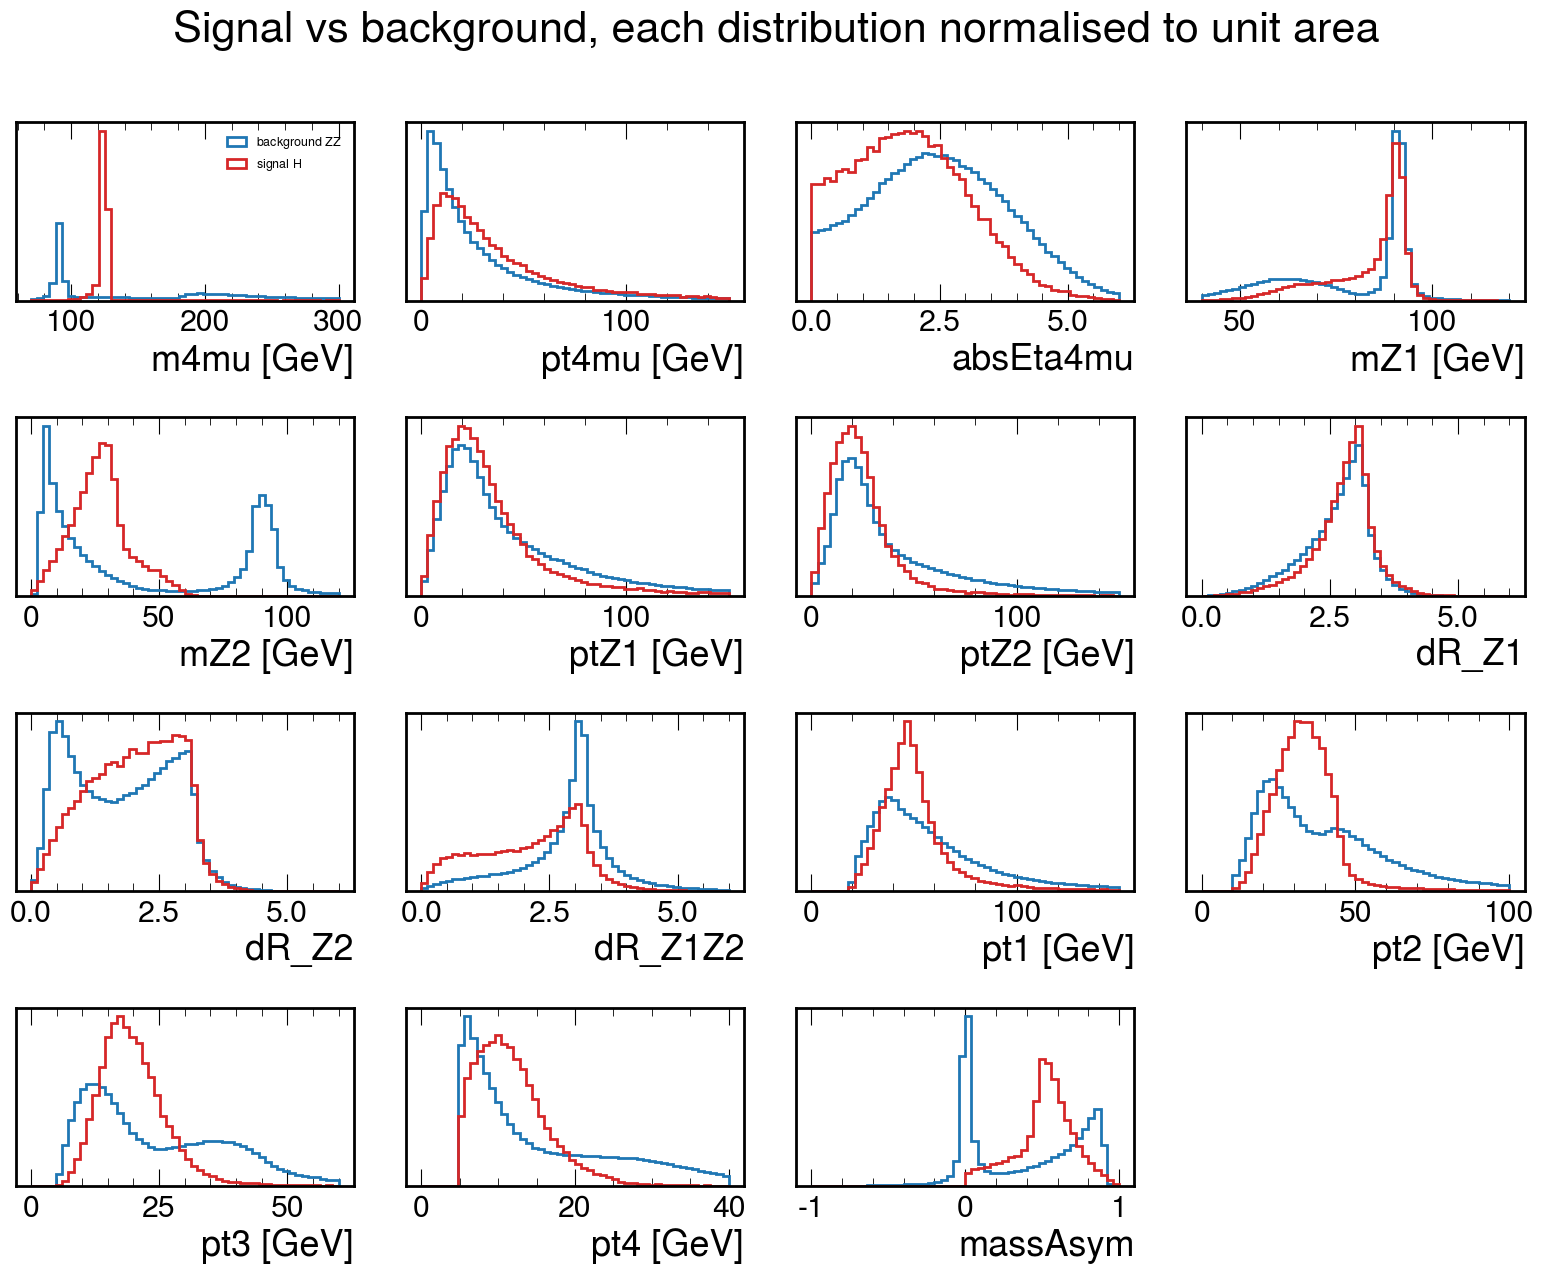

In [13]:
n_sig = len(data["signal"]["m4mu"])
n_bkg = len(data["background"]["m4mu"])
print(f"signal     events passing selection: {n_sig:>7,}")
print(f"background events passing selection: {n_bkg:>7,}")
print(f"signal fraction: {100*n_sig/(n_sig+n_bkg):.1f}%   <- imbalanced, we deal with this in Part 2")

RANGES = {"m4mu": (70, 300), "pt4mu": (0, 150), "absEta4mu": (0, 6), "mZ1": (40, 120),
          "mZ2": (0, 120), "ptZ1": (0, 150), "ptZ2": (0, 150), "dR_Z1": (0, 6),
          "dR_Z2": (0, 6), "dR_Z1Z2": (0, 6), "pt1": (0, 150), "pt2": (0, 100),
          "pt3": (0, 60), "pt4": (0, 40), "massAsym": (-1,1)}

fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, name in zip(axes.flat, FEATURE_NAMES):
    lo, hi = RANGES[name]
    bins = np.linspace(lo, hi, 51)                       # 50 bins
    ax.hist(data["background"][name], bins=bins, histtype="step", lw=2,
            density=True, label="background $ZZ$", color="tab:blue")
    ax.hist(data["signal"][name], bins=bins, histtype="step", lw=2,
            density=True, label="signal $H$", color="tab:red")
    ax.set_xlabel(name + ("" if name.startswith(("dR", "abs", "massAsym")) else " [GeV]"))
    ax.set_yticks([])
for ax in axes.flat[len(FEATURE_NAMES):]:
    ax.axis("off")
axes.flat[0].legend(fontsize=9)
fig.suptitle("Signal vs background, each distribution normalised to unit area", y=0.995)
plt.tight_layout(); plt.show()

Signal
OG: 47225
Cut: 44474
% Kept: 94.17%

Background
OG: 630400
Cut: 29539
% Kept: 4.69%
Mean: 184.53
Std dev: 130.91


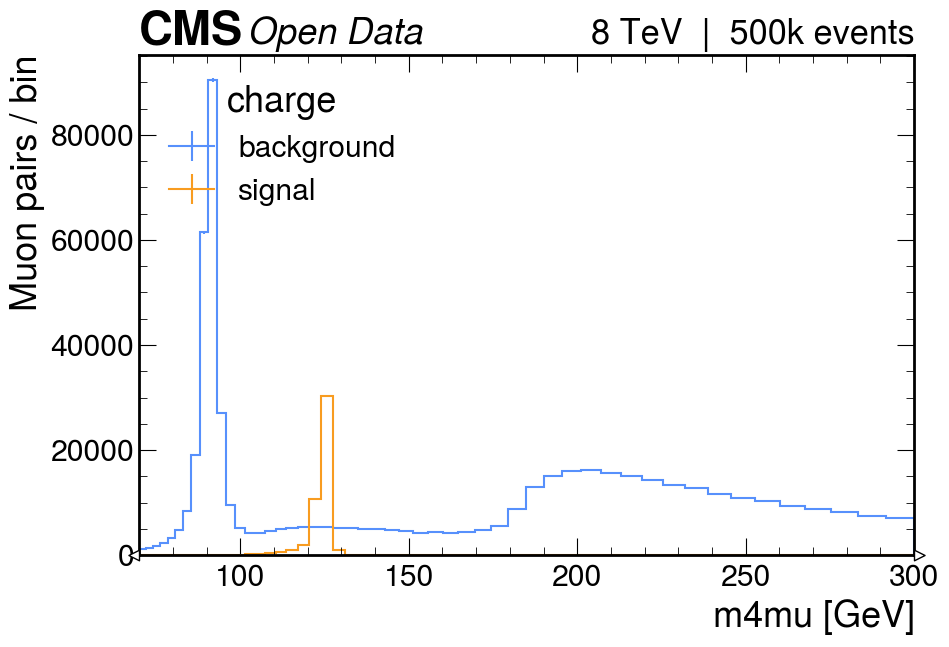

In [9]:
#Mass cut:
sig_mass_range = (data["signal"]["m4mu"] > 115) & (data["signal"]["m4mu"] < 135)

sig_array = ak.Array(data["signal"]["m4mu"])
before = len(data["signal"]["m4mu"])
after = len(sig_array[sig_mass_range])

print("Signal")
print("OG:", before)
print("Cut:", after)
print(f"% Kept: {100*after/before:.2f}%")
print()


bkg_mass_range = (data["background"]["m4mu"] > 115) & (data["background"]["m4mu"] < 135)

bkg_array = ak.Array(data["background"]["m4mu"])
before = len(data["background"]["m4mu"])
after = len(bkg_array[bkg_mass_range])

print("Background")
print("OG:", before)
print("Cut:", after)
print(f"% Kept: {100*after/before:.2f}%")
print("Mean:", f"{ak.mean(bkg_array):.2f}")
print("Std dev:", f"{ak.std(bkg_array):.2f}")

h_mass = (
    hist.Hist.new
    .StrCat(["background", "signal"], name="data", label="m4mu")
    .Log(51, 70.0, 300.0, name="mass", label=r"$m4mu$ [GeV]")
    .Int64()
)

h_mass.fill(data="background", mass=bkg_array)
h_mass.fill(data="signal", mass=sig_array)

fig, ax = plt.subplots(figsize=(10, 6.5))
h_mass.plot1d(ax=ax, overlay="data")
# ax.set_xscale("log")
# ax.set_yscale("log")
ax.set_xlim(70, 300)
ax.set_ylabel("Muon pairs / bin")
ax.legend(title="charge", loc="upper left")
hep.cms.label("Open Data", data=True, ax=ax, loc=0, rlabel="8 TeV  |  500k events")
plt.show()

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep

hep.style.use("CMS")

# ----------------------------------------------------------------------
# 1. Binning + accumulation
# ----------------------------------------------------------------------
def fill(values, bins, weights=None):
    """Histogram one dataset. Returns (sum of weights, sum of weights^2) per bin."""
    values = np.asarray(values)
    w = np.ones(len(values)) if weights is None else np.asarray(weights)
    sumw,  _ = np.histogram(values, bins=bins, weights=w)
    sumw2, _ = np.histogram(values, bins=bins, weights=w**2)
    return sumw, sumw2


def accumulate(datasets, bins):
    """
    datasets : list of dicts, each {"values": array, "weights": array or None}
    Returns total counts and their uncertainty (errors add in quadrature).
    """
    total  = np.zeros(len(bins) - 1)
    total2 = np.zeros(len(bins) - 1)
    for d in datasets:
        sw, sw2 = fill(d["values"], bins, d.get("weights"))
        total  += sw
        total2 += sw2
    return total, np.sqrt(total2)


# ----------------------------------------------------------------------
# 2. Plot
# ----------------------------------------------------------------------
def scatter_plot(datasets, bins, xlabel="", ylabel=None, label="Data",
                 lumi=None, com=13, cms_text="Work in Progress",
                 logy=False, outname=None):
    counts, err = accumulate(datasets, bins)
    centers = 0.5 * (bins[1:] + bins[:-1])
    xerr    = 0.5 * (bins[1:] - bins[:-1])      # horizontal bars = bin width

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.errorbar(centers, counts, yerr=err, xerr=xerr,
                fmt="ko", markersize=4, elinewidth=1, label=label)

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel or f"Events / {bins[1] - bins[0]:.3g}")
    ax.set_xlim(bins[0], bins[-1])
    if logy:
        ax.set_yscale("log")
    else:
        ax.set_ylim(bottom=0)
    ax.legend(loc="upper right")

    hep.cms.label(cms_text, data=True, lumi=lumi, com=com, ax=ax)
    if outname:
        fig.savefig(outname, dpi=200, bbox_inches="tight")
    return fig, ax, counts, err


# ----------------------------------------------------------------------
# 3. YOUR DATA GOES HERE
# ----------------------------------------------------------------------
bins = np.linspace(0, 100, 41)          # <- same bins for both datasets

fig, ax, counts, err = scatter_plot(
    [np.array(sig_array), np.array(bkg_array)],
    bins,
    xlabel=r"Mass [GeV]",
    lumi=None,          # e.g. 11.6 (fb$^{-1}$); None hides it
    com=13,             # TeV
)
plt.show()

IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices